# 08 - Hybrid Quantum Metric Learning for Iris Verification

## Objective

This is the main experiment of the project. It trains the **complete hybrid
model end to end**:

```
Iris image ─► ResNet34 encoder ─► 128-D ─► classical projection ─► 8-D (L2-norm)
                                                                     │
                                         8-qubit variational circuit (Notebook 7)
                                                                     │
                                                         8-D quantum embedding ─► contrastive loss
```

Notebook 7 showed that, on *frozen* embeddings, the circuit matches classical
heads (test AUC 0.8755 vs 0.8765-0.8769) but does not beat them. The only
place a quantum benefit could still appear is when the encoder, the projection
and the circuit are **optimised together** with augmented images. This
notebook tests exactly that, with controls.

## Models compared (identical data, pairs, schedule and selection rule)

| Variant | Head after the 8-D projection | Purpose |
|---|---|---|
| `hybrid_quantum` | 8-qubit VQC from Notebook 7 (CNOT ring) | the proposed model |
| `classical_linear` | 8×8 linear layer (identity-initialised) | classical control |
| `hybrid_quantum_product` | same VQC, **no entanglement** | does entanglement matter? |
| *reference* | none (Notebook 6 model, no further training) | where training starts |

## Training schedule (two phases)

1. **Head warm-up** (few epochs): encoder and projection are frozen and only the
   new head is trained, so a randomly initialised head cannot damage the
   good Notebook 6 features.
2. **Joint fine-tuning**: everything is trained with small learning rates
   (encoder smallest), early stopping on validation AUC.

## Experimental Protocol

- Identity-disjoint train / validation / test splits (Notebook 3).
- **The same validation and test pairs as Notebooks 5, 6 and 7.**
- Training pairs are identical across variants (same seed → same pairs).
- Model selection and the threshold use validation data only.
- Test is evaluated once per variant with the validation threshold.
- Differences are judged with a **paired bootstrap over the test pairs**
  (95% confidence interval), not just by comparing point estimates.

## Outputs

1. Trained hybrid and control models (checkpoints).
2. Verification accuracy, AUC, EER, FAR, FRR for every variant.
3. Paired-bootstrap comparison between variants and against Notebook 6.
4. 8-D embeddings for every split (for few-shot evaluation in Notebook 9).
5. Configuration files to rebuild each model.

## Runtime

Each variant trains for up to 3 + 30 epochs at roughly the cost of a
Notebook 6 epoch plus a small simulator overhead. Training is **resumable**:
a finished variant is skipped on re-run (`RESUME = True`).

In [1]:
# ============================================================
# CELL 2: Import libraries
# ============================================================

import os
import sys
import json
import math
import copy
import time
import random
import importlib
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from PIL import Image

from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    roc_curve,
    roc_auc_score
)

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.data import (
    Dataset,
    DataLoader
)

from torchvision import transforms

from torchvision.models import (
    resnet18, ResNet18_Weights,
    resnet34, ResNet34_Weights,
    resnet50, ResNet50_Weights,
)


print("All libraries imported successfully.")
print("PyTorch:", torch.__version__)

All libraries imported successfully.
PyTorch: 2.14.1+cu126


In [2]:
# ============================================================
# CELL 3: Reproducibility
# ============================================================

SEED = 42


def set_seed(seed=SEED):

    random.seed(seed)

    np.random.seed(seed)

    torch.manual_seed(seed)

    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True

    torch.backends.cudnn.benchmark = False


set_seed()


print(f"Random seed set to: {SEED}")

Random seed set to: 42


In [3]:
# ============================================================
# CELL 4: Configuration
# ============================================================


# ------------------------------------------------------------
# Input directories
# ------------------------------------------------------------

DATA_SPLITS_ROOT = Path("../data_splits")                    # Notebook 3

NB5_DIR = Path("../siamese_metric_learning")                  # Notebook 5

NB6_DIR = Path("../classical_projection_baseline")            # Notebook 6

NB7_DIR = Path("../quantum_circuit_experiments")              # Notebook 7


# ------------------------------------------------------------
# Notebook 8 output directory
# ------------------------------------------------------------

OUTPUT_DIR = Path("../hybrid_quantum_metric_learning")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# Which variants to train (comment lines out to skip)
# ------------------------------------------------------------

RUN_VARIANTS = [
    "hybrid_quantum",
    "classical_linear",
    "hybrid_quantum_product",
]

RESUME = True                  # skip variants that already have a checkpoint

QUICK_TEST = False             # tiny run (~10 min) to check the pipeline


# ------------------------------------------------------------
# Image configuration (must match Notebooks 5-6)
# ------------------------------------------------------------

IMAGE_SIZE = 224


# ------------------------------------------------------------
# Training configuration
# ------------------------------------------------------------

BATCH_SIZE = 16                # PAIRS per batch = 32 images

PHASE1_EPOCHS = 3              # head only (encoder + projection frozen)

PHASE2_EPOCHS = 30             # joint fine-tuning (max)

PATIENCE = 10                  # counted in phase 2 only

HEAD_LR_PHASE1 = 0.02          # same as Notebook 7

HEAD_LR_PHASE2 = 0.005

PROJECTION_LR = 1e-4

ENCODER_LR = 1e-5

WEIGHT_DECAY = 5e-4            # not applied to the head (circuit angles)

NUM_WORKERS = 0                # Windows-safe

TRAIN_PAIRS_PER_EPOCH = 6400


# ------------------------------------------------------------
# Statistics
# ------------------------------------------------------------

BOOTSTRAP_SAMPLES = 1000


if QUICK_TEST:

    PHASE1_EPOCHS = 1

    PHASE2_EPOCHS = 1

    TRAIN_PAIRS_PER_EPOCH = 320

    BOOTSTRAP_SAMPLES = 100


# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# The circuit simulator runs on the same device as the network.
# fp16 / AMP stays off (NaNs on GTX 16-series; complex numbers anyway).


print("Output directory:", OUTPUT_DIR)

print("Variants:", RUN_VARIANTS)

print("Device:", DEVICE)

print("Epochs: phase 1 =", PHASE1_EPOCHS, " phase 2 (max) =", PHASE2_EPOCHS)

print("Quick test mode:", QUICK_TEST)

Output directory: ..\hybrid_quantum_metric_learning
Variants: ['hybrid_quantum', 'classical_linear', 'hybrid_quantum_product']
Device: cuda
Epochs: phase 1 = 3  phase 2 (max) = 30
Quick test mode: False


In [4]:
# ============================================================
# CELL 5: Verify inputs from earlier notebooks
# ============================================================

NB6_MODEL_PATH = NB6_DIR / "best_classical_projection_model.pth"

NB6_CONFIG_PATH = NB6_DIR / "model_config.json"

CIRCUIT_CONFIG_PATH = NB7_DIR / "best_circuit_config.json"

QUANTUM_SIM_PATH = NB7_DIR / "quantum_sim.py"

VALIDATION_PAIRS_PATH = NB6_DIR / "validation_pairs.csv"

TEST_PAIRS_PATH = NB6_DIR / "test_pairs.csv"


required = {
    "Notebook 3 splits": DATA_SPLITS_ROOT,
    "Notebook 6 model": NB6_MODEL_PATH,
    "Notebook 6 config": NB6_CONFIG_PATH,
    "Notebook 6 validation pairs": VALIDATION_PAIRS_PATH,
    "Notebook 6 test pairs": TEST_PAIRS_PATH,
    "Notebook 7 circuit config": CIRCUIT_CONFIG_PATH,
    "Notebook 7 quantum_sim.py": QUANTUM_SIM_PATH,
}

for name, path in required.items():

    print(f"{name:30s}", "FOUND" if path.exists() else "MISSING", "-", path)

    if not path.exists():

        raise FileNotFoundError(f"{path} not found. Run earlier notebooks first.")


with open(NB6_CONFIG_PATH) as file:

    NB6_CONFIG = json.load(file)

with open(CIRCUIT_CONFIG_PATH) as file:

    CIRCUIT_CONFIG = json.load(file)


CONTRASTIVE_MARGIN = CIRCUIT_CONFIG.get("contrastive_margin", 1.0)


print("\nNotebook 6 model config:", NB6_CONFIG)

print("\nNotebook 7 circuit config:", CIRCUIT_CONFIG)

Notebook 3 splits              FOUND - ..\data_splits
Notebook 6 model               FOUND - ..\classical_projection_baseline\best_classical_projection_model.pth
Notebook 6 config              FOUND - ..\classical_projection_baseline\model_config.json
Notebook 6 validation pairs    FOUND - ..\classical_projection_baseline\validation_pairs.csv
Notebook 6 test pairs          FOUND - ..\classical_projection_baseline\test_pairs.csv
Notebook 7 circuit config      FOUND - ..\quantum_circuit_experiments\best_circuit_config.json
Notebook 7 quantum_sim.py      FOUND - ..\quantum_circuit_experiments\quantum_sim.py

Notebook 6 model config: {'backbone': 'resnet34', 'encoder_embedding_dim': 128, 'projection_dim': 8, 'projection_hidden': 64, 'projection_dropout': 0.1, 'image_size': 224, 'normalize_mean': [0.485, 0.456, 0.406], 'normalize_std': [0.229, 0.224, 0.225]}

Notebook 7 circuit config: {'n_qubits': 8, 'encoding': ['RY'], 'entanglement': 'ring', 'entangler': 'CNOT', 'input_scale': 1.0, 'n_la

In [5]:
# ============================================================
# CELL 6: Load Notebook 3 splits, verify paths and identities
# ============================================================

def find_csv(possible_names):

    for name in possible_names:

        path = DATA_SPLITS_ROOT / name

        if path.exists():

            return path

    raise FileNotFoundError(f"None of {possible_names} found.")


train_df = pd.read_csv(find_csv(["train.csv", "training.csv"]))

validation_df = pd.read_csv(find_csv(["validation.csv", "val.csv"]))

test_df = pd.read_csv(find_csv(["test.csv"]))


IDENTITY_COLUMN = next(
    c for c in ["identity", "eye_id", "subject_id", "class_id", "label"]
    if c in train_df.columns
)

PATH_COLUMN = next(
    c for c in ["processed_path", "image_path", "path", "filepath", "file_path"]
    if c in train_df.columns
)


def resolve_image_path(path_value):

    path = Path(str(path_value))

    for candidate in [path, DATA_SPLITS_ROOT / path, Path.cwd() / path]:

        if candidate.exists():

            return str(candidate.resolve())

    return str(path)


for dataframe in [train_df, validation_df, test_df]:

    dataframe[PATH_COLUMN] = dataframe[PATH_COLUMN].apply(resolve_image_path)


for name, dataframe in [
    ("Training", train_df), ("Validation", validation_df), ("Test", test_df)
]:

    missing = (~dataframe[PATH_COLUMN].apply(lambda p: Path(p).exists())).sum()

    print(f"{name:11s} images: {len(dataframe):6d}   "
          f"identities: {dataframe[IDENTITY_COLUMN].nunique():5d}   "
          f"missing: {missing}")

    if missing:

        raise FileNotFoundError(f"{name} split has missing image files.")


train_ids = set(train_df[IDENTITY_COLUMN])

validation_ids = set(validation_df[IDENTITY_COLUMN])

test_ids = set(test_df[IDENTITY_COLUMN])

assert not (train_ids & validation_ids)

assert not (train_ids & test_ids)

assert not (validation_ids & test_ids)

print("\n✓ Identity-disjoint splits verified.")

Training    images:  14000   identities:  1400   missing: 0
Validation  images:   3000   identities:   300   missing: 0
Test        images:   3000   identities:   300   missing: 0

✓ Identity-disjoint splits verified.


In [6]:
# ============================================================
# CELL 7: Image transformations (identical to Notebooks 5-6)
# ============================================================

NORMALIZE_MEAN = NB6_CONFIG.get("normalize_mean", [0.485, 0.456, 0.406])

NORMALIZE_STD = NB6_CONFIG.get("normalize_std", [0.229, 0.224, 0.225])


train_transform = transforms.Compose(
    [
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

        transforms.RandomApply(
            [
                transforms.RandomAffine(
                    degrees=10,
                    translate=(0.06, 0.06),
                    scale=(0.90, 1.10),
                    shear=4,
                    fill=0
                )
            ],
            p=0.8
        ),

        transforms.ColorJitter(brightness=0.30, contrast=0.30),

        transforms.RandomApply(
            [transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.2))],
            p=0.25
        ),

        transforms.ToTensor(),

        transforms.Normalize(mean=NORMALIZE_MEAN, std=NORMALIZE_STD),

        transforms.RandomErasing(
            p=0.30, scale=(0.02, 0.12), ratio=(0.3, 3.3), value=0
        )
    ]
)


evaluation_transform = transforms.Compose(
    [
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

        transforms.ToTensor(),

        transforms.Normalize(mean=NORMALIZE_MEAN, std=NORMALIZE_STD)
    ]
)


print("Image transformations configured.")

Image transformations configured.


In [7]:
# ============================================================
# CELL 8: Pair datasets
# ============================================================
#
# Label convention: 0 = same identity (genuine), 1 = different (impostor)

class SiamesePairDataset(Dataset):

    def __init__(
        self, dataframe, identity_column, path_column,
        num_pairs, transform=None, seed=42
    ):

        self.dataframe = dataframe.reset_index(drop=True).copy()

        self.identity_column = identity_column

        self.path_column = path_column

        self.num_pairs = num_pairs

        self.transform = transform

        self.seed = seed

        self.identity_to_indices = {
            identity: group.index.tolist()
            for identity, group in self.dataframe.groupby(identity_column)
        }

        self.identities = list(self.identity_to_indices.keys())

        self.valid_positive_ids = [
            identity for identity, indices in self.identity_to_indices.items()
            if len(indices) >= 2
        ]

        self.create_pairs()

    def create_pairs(self):

        rng = random.Random(self.seed)

        self.pairs = []

        num_positive = self.num_pairs // 2

        num_negative = self.num_pairs - num_positive

        for _ in range(num_positive):

            identity = rng.choice(self.valid_positive_ids)

            index1, index2 = rng.sample(self.identity_to_indices[identity], 2)

            self.pairs.append((index1, index2, 0.0))

        for _ in range(num_negative):

            identity1, identity2 = rng.sample(self.identities, 2)

            index1 = rng.choice(self.identity_to_indices[identity1])

            index2 = rng.choice(self.identity_to_indices[identity2])

            self.pairs.append((index1, index2, 1.0))

        rng.shuffle(self.pairs)

    def regenerate_pairs(self, epoch):

        self.seed = SEED + epoch

        self.create_pairs()

    def __len__(self):

        return len(self.pairs)

    def __getitem__(self, index):

        index1, index2, label = self.pairs[index]

        image1 = Image.open(
            self.dataframe.iloc[index1][self.path_column]
        ).convert("RGB")

        image2 = Image.open(
            self.dataframe.iloc[index2][self.path_column]
        ).convert("RGB")

        if self.transform is not None:

            image1 = self.transform(image1)

            image2 = self.transform(image2)

        return image1, image2, torch.tensor(label, dtype=torch.float32)


class FixedPairDataset(Dataset):

    def __init__(self, pairs_dataframe, transform=None):

        self.pairs_dataframe = pairs_dataframe.reset_index(drop=True)

        self.transform = transform

    def __len__(self):

        return len(self.pairs_dataframe)

    def __getitem__(self, index):

        row = self.pairs_dataframe.iloc[index]

        image1 = Image.open(row["image1_path"]).convert("RGB")

        image2 = Image.open(row["image2_path"]).convert("RGB")

        if self.transform is not None:

            image1 = self.transform(image1)

            image2 = self.transform(image2)

        return (
            image1, image2,
            torch.tensor(float(row["label"]), dtype=torch.float32)
        )


print("Pair dataset classes defined.")

Pair dataset classes defined.


In [8]:
# ============================================================
# CELL 9: Create datasets and DataLoaders
# ============================================================

train_pair_dataset = SiamesePairDataset(
    dataframe=train_df,
    identity_column=IDENTITY_COLUMN,
    path_column=PATH_COLUMN,
    num_pairs=TRAIN_PAIRS_PER_EPOCH,
    transform=train_transform,
    seed=SEED
)


validation_pairs_df = pd.read_csv(VALIDATION_PAIRS_PATH)

test_pairs_df = pd.read_csv(TEST_PAIRS_PATH)

for name, pairs_df in [("validation", validation_pairs_df),
                       ("test", test_pairs_df)]:

    missing = sum(
        not Path(p).exists()
        for p in list(pairs_df["image1_path"]) + list(pairs_df["image2_path"])
    )

    if missing:

        raise FileNotFoundError(
            f"{missing} images of the Notebook 6 {name} pairs were not found."
        )


validation_pair_dataset = FixedPairDataset(validation_pairs_df, evaluation_transform)

test_pair_dataset = FixedPairDataset(test_pairs_df, evaluation_transform)


loader_kwargs = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": DEVICE.type == "cuda"
}

train_loader = DataLoader(
    train_pair_dataset, shuffle=True, drop_last=True, **loader_kwargs
)

validation_loader = DataLoader(
    validation_pair_dataset, shuffle=False, **loader_kwargs
)

test_loader = DataLoader(
    test_pair_dataset, shuffle=False, **loader_kwargs
)


print("Training pairs per epoch:", len(train_pair_dataset))

print("Validation pairs:", len(validation_pair_dataset),
      "(Notebook 6 pairs)")

print("Test pairs:", len(test_pair_dataset), "(Notebook 6 pairs)")

Training pairs per epoch: 6400
Validation pairs: 5000 (Notebook 6 pairs)
Test pairs: 5000 (Notebook 6 pairs)


## Model definition

The classical part is **identical to Notebook 6** (same class and attribute
names), so its trained weights load directly. The circuit comes from
`quantum_sim.py`, written by Notebook 7, so the exact simulated circuit that
was designed there is the one trained here.

In [9]:
# ============================================================
# CELL 11: Encoder, projection head, hybrid model
# ============================================================

sys.path.insert(0, str(NB7_DIR.resolve()))

import quantum_sim

importlib.reload(quantum_sim)

from quantum_sim import QuantumCircuitEmbedder, describe_circuit


def build_backbone(name, pretrained=False):

    if name == "resnet18":

        trunk = resnet18(weights=ResNet18_Weights.DEFAULT if pretrained else None)

    elif name == "resnet34":

        trunk = resnet34(weights=ResNet34_Weights.DEFAULT if pretrained else None)

    elif name == "resnet50":

        trunk = resnet50(weights=ResNet50_Weights.DEFAULT if pretrained else None)

    else:

        raise ValueError(f"Unknown backbone: {name}")

    num_features = trunk.fc.in_features

    trunk.fc = nn.Identity()

    return trunk, num_features


class SiameseEncoder(nn.Module):

    def __init__(self, embedding_dim=128, backbone_name="resnet34",
                 dropout=0.2, pretrained=False):

        super().__init__()

        self.backbone, num_features = build_backbone(backbone_name, pretrained)

        self.embedding_layer = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(num_features, embedding_dim, bias=False),
            nn.BatchNorm1d(embedding_dim)
        )

    def forward(self, x):

        return F.normalize(self.embedding_layer(self.backbone(x)), p=2, dim=1)


class ProjectionHead(nn.Module):

    def __init__(self, in_dim=128, out_dim=8, hidden_dim=64, dropout=0.1):

        super().__init__()

        if hidden_dim and hidden_dim > 0:

            self.net = nn.Sequential(
                nn.Linear(in_dim, hidden_dim, bias=False),
                nn.BatchNorm1d(hidden_dim),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.Linear(hidden_dim, out_dim, bias=False),
                nn.BatchNorm1d(out_dim)
            )

        else:

            self.net = nn.Sequential(
                nn.Linear(in_dim, out_dim, bias=False),
                nn.BatchNorm1d(out_dim)
            )

    def forward(self, x):

        return F.normalize(self.net(x), p=2, dim=1)


class LinearHead(nn.Module):

    # Classical control: 8x8 matrix, identity-initialised, L2-normalised

    def __init__(self, dim=8):

        super().__init__()

        self.linear = nn.Linear(dim, dim, bias=False)

        with torch.no_grad():

            self.linear.weight.copy_(
                torch.eye(dim) + 0.01 * torch.randn(dim, dim)
            )

    def forward(self, x):

        return F.normalize(self.linear(x), p=2, dim=1, eps=1e-6)


class HybridSiamese(nn.Module):

    def __init__(self, encoder, projection, head=None):

        super().__init__()

        self.encoder = encoder

        self.projection = projection

        self.head = head                      # None = Notebook 6 model

    def embed_pre(self, x):

        # 8-D embedding BEFORE the new head (Notebook 6 output)

        return self.projection(self.encoder(x))

    def embed(self, x):

        pre = self.embed_pre(x)

        return pre if self.head is None else self.head(pre)

    def forward(self, image1, image2):

        return self.embed(image1), self.embed(image2)


VARIANT_SPECS = {
    "hybrid_quantum": {"head": "quantum", "overrides": {}},
    "classical_linear": {"head": "linear", "overrides": {}},
    "hybrid_quantum_product": {
        "head": "quantum", "overrides": {"entanglement": "none"}
    },
    "reference_nb6": {"head": None, "overrides": {}},
}


def circuit_kwargs(overrides):

    kwargs = {
        k: v for k, v in CIRCUIT_CONFIG.items()
        if k not in ("learning_rate", "contrastive_margin")
    }

    kwargs.update(overrides)

    return kwargs


def build_hybrid(variant, seed=SEED):

    spec = VARIANT_SPECS[variant]

    torch.manual_seed(seed)

    encoder = SiameseEncoder(
        embedding_dim=NB6_CONFIG["encoder_embedding_dim"],
        backbone_name=NB6_CONFIG["backbone"],
        pretrained=False
    )

    projection = ProjectionHead(
        in_dim=NB6_CONFIG["encoder_embedding_dim"],
        out_dim=NB6_CONFIG["projection_dim"],
        hidden_dim=NB6_CONFIG["projection_hidden"],
        dropout=NB6_CONFIG["projection_dropout"]
    )

    state = torch.load(
        NB6_MODEL_PATH, map_location="cpu", weights_only=False
    )["model_state_dict"]

    encoder.load_state_dict(
        {k[len("encoder."):]: v for k, v in state.items()
         if k.startswith("encoder.")}
    )

    projection.load_state_dict(
        {k[len("projection."):]: v for k, v in state.items()
         if k.startswith("projection.")}
    )

    if spec["head"] == "quantum":

        head = QuantumCircuitEmbedder(**circuit_kwargs(spec["overrides"]))

    elif spec["head"] == "linear":

        head = LinearHead(NB6_CONFIG["projection_dim"])

    else:

        head = None

    return HybridSiamese(encoder, projection, head).to(DEVICE)


def count_parameters(module):

    return sum(p.numel() for p in module.parameters())


print("Model definitions ready.\n")

print("Circuit used for the quantum variants:\n")

print(describe_circuit(
    {**{k: tuple(v) if isinstance(v, list) else v
        for k, v in circuit_kwargs({}).items()}},
    CIRCUIT_CONFIG["n_qubits"]
))

Model definitions ready.

Circuit used for the quantum variants:

Qubits        : 8
Encoding      : RY(scale * x_i) on qubit i   scale = 1.0000
Layers        : 3 x [ RY+RZ(theta) on every qubit -> CNOT ring ]
Entangling    : [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 6), (6, 7), (7, 0)]
Measurement   : <Z> on every qubit -> 8-D embedding
Trainable     : 48 parameters


In [10]:
# ============================================================
# CELL 12: Loss, metrics, training and evaluation functions
# ============================================================

class ContrastiveLoss(nn.Module):

    def __init__(self, margin=1.0):

        super().__init__()

        self.margin = margin

    def forward(self, embedding1, embedding2, labels):

        distances = F.pairwise_distance(embedding1, embedding2)

        genuine_loss = (1 - labels) * distances.pow(2)

        impostor_loss = labels * torch.clamp(
            self.margin - distances, min=0.0
        ).pow(2)

        return (genuine_loss + impostor_loss).mean(), distances


criterion = ContrastiveLoss(margin=CONTRASTIVE_MARGIN)


def predict_from_distance(distances, threshold):

    return (distances > threshold).astype(int)      # 0 = same identity


def calculate_far_frr(distances, labels, threshold):

    predictions = predict_from_distance(distances, threshold)

    genuine = labels == 0

    impostor = labels == 1

    frr = np.sum(predictions[genuine] == 1) / max(genuine.sum(), 1)

    far = np.sum(predictions[impostor] == 0) / max(impostor.sum(), 1)

    return far, frr


def get_validation_metrics(distances, labels):

    genuine_labels = 1 - labels

    scores = -distances

    fpr, tpr, roc_thresholds = roc_curve(genuine_labels, scores)

    auc_score = roc_auc_score(genuine_labels, scores)

    best_index = np.argmax(tpr - fpr)

    threshold = -roc_thresholds[best_index]

    accuracy = accuracy_score(labels, predict_from_distance(distances, threshold))

    fnr = 1 - tpr

    eer_index = np.argmin(np.abs(fpr - fnr))

    eer = (fpr[eer_index] + fnr[eer_index]) / 2

    return {
        "accuracy": accuracy, "auc": auc_score, "threshold": threshold,
        "eer": eer, "eer_threshold": -roc_thresholds[eer_index],
        "fpr": fpr, "tpr": tpr
    }


def evaluate_model(model, dataloader):

    model.eval()

    running_loss = 0.0

    all_distances, all_labels = [], []

    with torch.no_grad():

        for image1, image2, labels in tqdm(
            dataloader, desc="Evaluating", leave=False
        ):

            image1 = image1.to(DEVICE, non_blocking=True)

            image2 = image2.to(DEVICE, non_blocking=True)

            labels = labels.to(DEVICE, non_blocking=True)

            embedding1, embedding2 = model(image1, image2)

            loss, distances = criterion(embedding1, embedding2, labels)

            running_loss += loss.item() * image1.size(0)

            all_distances.extend(distances.cpu().numpy())

            all_labels.extend(labels.cpu().numpy())

    return (
        running_loss / len(dataloader.dataset),
        np.array(all_distances),
        np.array(all_labels)
    )


def set_phase(model, phase):

    # Phase 1: only the new head trains.  Phase 2: everything trains.

    train_backbone = phase == 2

    for parameter in model.encoder.parameters():

        parameter.requires_grad = train_backbone

    for parameter in model.projection.parameters():

        parameter.requires_grad = train_backbone

    for parameter in model.head.parameters():

        parameter.requires_grad = True


def train_one_epoch(model, dataloader, optimizer, phase):

    model.train()

    if phase == 1:

        model.encoder.eval()        # freeze BatchNorm statistics / dropout

        model.projection.eval()

    running_loss, seen = 0.0, 0

    for image1, image2, labels in tqdm(dataloader, desc="Training", leave=False):

        image1 = image1.to(DEVICE, non_blocking=True)

        image2 = image2.to(DEVICE, non_blocking=True)

        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad()

        embedding1, embedding2 = model(image1, image2)

        loss, _ = criterion(embedding1, embedding2, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            [p for p in model.parameters() if p.requires_grad], max_norm=5.0
        )

        optimizer.step()

        running_loss += loss.item() * image1.size(0)

        seen += image1.size(0)

    return running_loss / max(seen, 1)


def build_param_groups(module, lr, weight_decay):

    decay, no_decay = [], []

    for name, parameter in module.named_parameters():

        if parameter.ndim <= 1 or name.endswith(".bias"):

            no_decay.append(parameter)

        else:

            decay.append(parameter)

    return [
        {"params": decay, "lr": lr, "weight_decay": weight_decay},
        {"params": no_decay, "lr": lr, "weight_decay": 0.0},
    ]


print("Training machinery ready.")

Training machinery ready.


In [11]:
# ============================================================
# CELL 13: Reference - Notebook 6 model before any further training
# ============================================================

reference = build_hybrid("reference_nb6")

_, reference_val_distances, val_labels = evaluate_model(reference, validation_loader)

_, reference_test_distances, test_labels = evaluate_model(reference, test_loader)

reference_val = get_validation_metrics(reference_val_distances, val_labels)

reference_test_metrics = get_validation_metrics(reference_test_distances, test_labels)

reference_far, reference_frr = calculate_far_frr(
    reference_test_distances, test_labels, reference_val["threshold"]
)

reference_test_accuracy = accuracy_score(
    test_labels,
    predict_from_distance(reference_test_distances, reference_val["threshold"])
)

nb6_results = pd.read_csv(NB6_DIR / "final_results.csv").iloc[0]


print("Notebook 6 model re-evaluated here (starting point)")

print(f"  validation AUC: {reference_val['auc']:.4f}   (NB6: "
      f"{nb6_results['best_validation_auc']:.4f})")

print(f"  test AUC      : {reference_test_metrics['auc']:.4f}   (NB6: "
      f"{nb6_results['test_auc']:.4f})")

print(f"  test EER      : {reference_test_metrics['eer']:.4f}   (NB6: "
      f"{nb6_results['test_eer']:.4f})")

if abs(reference_test_metrics["auc"] - nb6_results["test_auc"]) > 2e-3:

    print("\n⚠ Does not reproduce Notebook 6 - check the checkpoint / pairs.")

else:

    print("\n✓ Notebook 6 model reproduced; training starts from here.")

del reference

if DEVICE.type == "cuda":

    torch.cuda.empty_cache()

Evaluating:   0%|          | 0/313 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/313 [00:00<?, ?it/s]

Notebook 6 model re-evaluated here (starting point)
  validation AUC: 0.8808   (NB6: 0.8808)
  test AUC      : 0.8747   (NB6: 0.8747)
  test EER      : 0.2218   (NB6: 0.2218)

✓ Notebook 6 model reproduced; training starts from here.


In [12]:
# ============================================================
# CELL 14: Train one variant (function)
# ============================================================

def checkpoint_path(variant):

    return OUTPUT_DIR / f"best_{variant}_seed{SEED}.pth"


def history_path(variant):

    return OUTPUT_DIR / f"history_{variant}_seed{SEED}.csv"


def is_done(variant):

    # history is written only when training finishes, so an interrupted
    # run (checkpoint but no history) is retrained rather than skipped

    return checkpoint_path(variant).exists() and history_path(variant).exists()


def train_variant(variant):

    if RESUME and is_done(variant):

        print(f"\n[{variant}] already trained - skipping "
              f"(set RESUME = False to retrain).")

        return

    print("\n" + "=" * 70)

    print(f"TRAINING VARIANT: {variant}")

    print("=" * 70)

    set_seed(SEED)

    model = build_hybrid(variant)

    print("Total parameters :", count_parameters(model))

    print("Head parameters  :", count_parameters(model.head))

    # ---------------- optimizer: one group set per component ------

    groups = (
        build_param_groups(model.encoder, ENCODER_LR, WEIGHT_DECAY)
        + build_param_groups(model.projection, PROJECTION_LR, WEIGHT_DECAY)
        + [{"params": list(model.head.parameters()),
            "lr": HEAD_LR_PHASE1, "weight_decay": 0.0}]
    )

    optimizer = optim.AdamW(groups)

    head_group = optimizer.param_groups[-1]

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=2
    )

    history = []

    best_auc = -np.inf

    stall = 0

    total_epochs = PHASE1_EPOCHS + PHASE2_EPOCHS

    for epoch in range(total_epochs):

        phase = 1 if epoch < PHASE1_EPOCHS else 2

        if epoch == PHASE1_EPOCHS:

            head_group["lr"] = HEAD_LR_PHASE2

        set_phase(model, phase)

        print(f"\n[{variant}] epoch {epoch + 1}/{total_epochs}  "
              f"(phase {phase}: "
              f"{'head only' if phase == 1 else 'joint fine-tuning'})")

        print("-" * 60)

        train_pair_dataset.regenerate_pairs(epoch)

        train_loss = train_one_epoch(model, train_loader, optimizer, phase)

        validation_loss, validation_distances, validation_labels = (
            evaluate_model(model, validation_loader)
        )

        metrics = get_validation_metrics(validation_distances, validation_labels)

        if phase == 2:

            scheduler.step(validation_loss)

        history.append(
            {
                "epoch": epoch + 1,
                "phase": phase,
                "train_loss": train_loss,
                "validation_loss": validation_loss,
                "validation_accuracy": metrics["accuracy"],
                "validation_auc": metrics["auc"],
                "validation_eer": metrics["eer"],
                "head_lr": head_group["lr"],
                "encoder_lr": optimizer.param_groups[0]["lr"]
            }
        )

        print(f"Train Loss: {train_loss:.4f}   "
              f"Validation Loss: {validation_loss:.4f}")

        print(f"Validation Accuracy: {metrics['accuracy']:.4f}   "
              f"AUC: {metrics['auc']:.4f}   EER: {metrics['eer']:.4f}")

        if metrics["auc"] > best_auc:

            best_auc = metrics["auc"]

            stall = 0

            torch.save(
                {
                    "variant": variant,
                    "seed": SEED,
                    "epoch": epoch + 1,
                    "model_state_dict": model.state_dict(),
                    "validation_loss": validation_loss,
                    "validation_accuracy": metrics["accuracy"],
                    "validation_auc": metrics["auc"],
                    "validation_eer": metrics["eer"],
                    "threshold": float(metrics["threshold"]),
                    "eer_threshold": float(metrics["eer_threshold"]),
                    "circuit_kwargs": (
                        circuit_kwargs(VARIANT_SPECS[variant]["overrides"])
                        if VARIANT_SPECS[variant]["head"] == "quantum" else None
                    )
                },
                checkpoint_path(variant)
            )

            print("✓ Best model saved.")

        elif phase == 2:

            stall += 1

            print(f"No validation AUC improvement. Patience: {stall}/{PATIENCE}")

            if stall >= PATIENCE:

                print("Early stopping triggered.")

                break

    pd.DataFrame(history).to_csv(history_path(variant), index=False)

    del model, optimizer

    if DEVICE.type == "cuda":

        torch.cuda.empty_cache()


print("Training function defined.")

Training function defined.


In [13]:
# ============================================================
# CELL 15: Run training for all variants
# ============================================================

training_start = time.time()

for variant in RUN_VARIANTS:

    variant_start = time.time()

    train_variant(variant)

    print(f"\n[{variant}] done in {(time.time() - variant_start) / 60:.1f} min")


print(f"\nTotal training time: {(time.time() - training_start) / 60:.1f} min")


TRAINING VARIANT: hybrid_quantum
Total parameters : 21359360
Head parameters  : 48

[hybrid_quantum] epoch 1/33  (phase 1: head only)
------------------------------------------------------------


Training:   0%|          | 0/400 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/313 [00:00<?, ?it/s]

Train Loss: 0.1332   Validation Loss: 0.1444
Validation Accuracy: 0.7914   AUC: 0.8753   EER: 0.2118
✓ Best model saved.

[hybrid_quantum] epoch 2/33  (phase 1: head only)
------------------------------------------------------------


Training:   0%|          | 0/400 [00:00<?, ?it/s]

...

Evaluating:   0%|          | 0/313 [00:00<?, ?it/s]

Train Loss: 0.1280   Validation Loss: 0.1405
Validation Accuracy: 0.7948   AUC: 0.8809   EER: 0.2096
No validation AUC improvement. Patience: 9/10

[hybrid_quantum_product] epoch 31/33  (phase 2: joint fine-tuning)
------------------------------------------------------------


Training:   0%|          | 0/400 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/313 [00:00<?, ?it/s]

Train Loss: 0.1277   Validation Loss: 0.1407
Validation Accuracy: 0.7956   AUC: 0.8805   EER: 0.2128
No validation AUC improvement. Patience: 10/10
Early stopping triggered.

[hybrid_quantum_product] done in 334.4 min

Total training time: 823.2 min


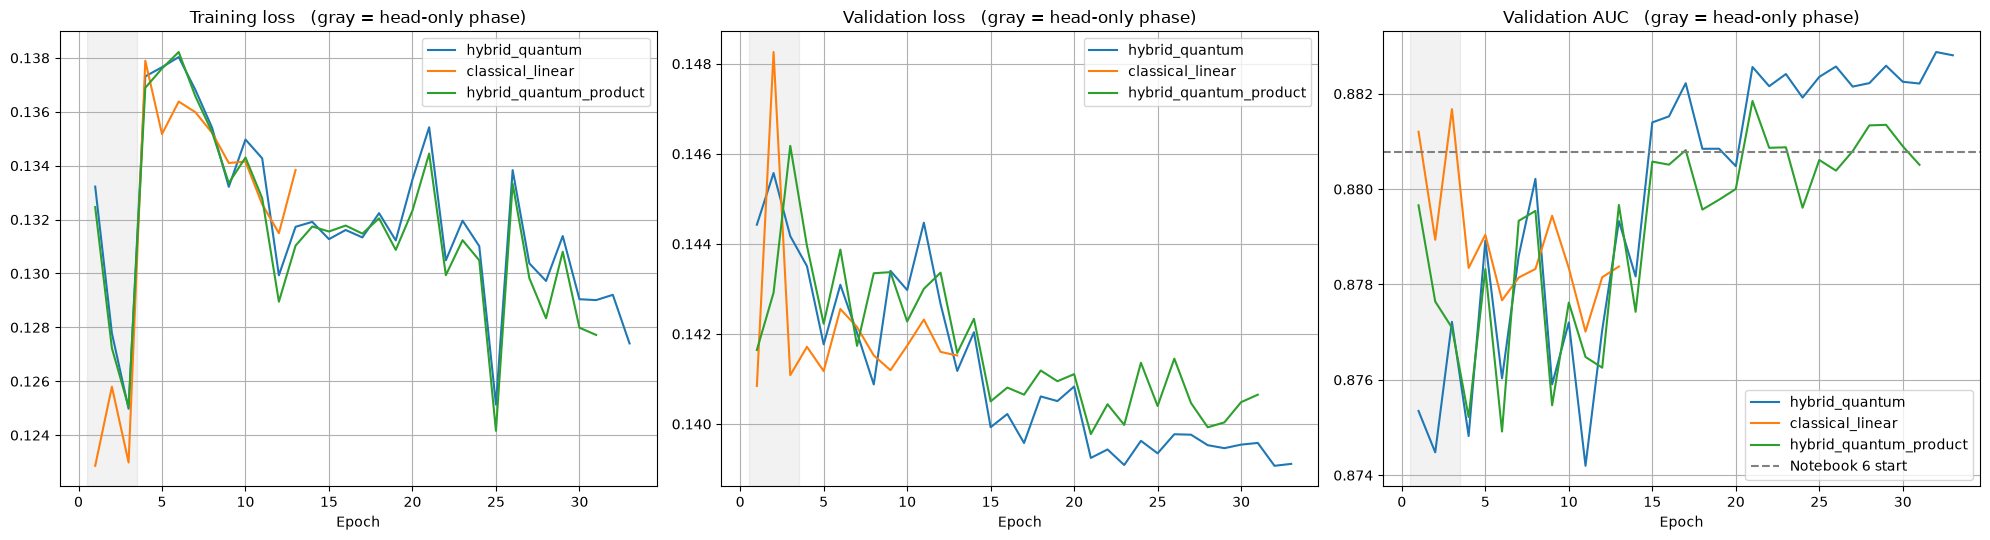

In [14]:
# ============================================================
# CELL 16: Training curves
# ============================================================

histories = {}

for variant in RUN_VARIANTS:

    if is_done(variant):

        histories[variant] = pd.read_csv(history_path(variant))


fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

for variant, history in histories.items():

    axes[0].plot(history["epoch"], history["train_loss"], label=variant)

    axes[1].plot(history["epoch"], history["validation_loss"], label=variant)

    axes[2].plot(history["epoch"], history["validation_auc"], label=variant)

axes[2].axhline(reference_val["auc"], linestyle="--", color="gray",
                label="Notebook 6 start")

for ax, title in zip(
    axes, ["Training loss", "Validation loss", "Validation AUC"]
):

    ax.axvspan(0.5, PHASE1_EPOCHS + 0.5, alpha=0.1, color="gray")

    ax.set_xlabel("Epoch")

    ax.set_title(title + "   (gray = head-only phase)")

    ax.grid(True)

    ax.legend()

plt.tight_layout()

plt.show()

In [15]:
# ============================================================
# CELL 17: Final test evaluation (threshold from validation only)
# ============================================================

variant_results = {}

for variant in RUN_VARIANTS:

    if not is_done(variant):

        print(f"[{variant}] not finished - skipped.")

        continue

    checkpoint = torch.load(
        checkpoint_path(variant), map_location=DEVICE, weights_only=False
    )

    model = build_hybrid(variant)

    model.load_state_dict(checkpoint["model_state_dict"])

    threshold = float(checkpoint["threshold"])

    test_loss, test_distances, labels = evaluate_model(model, test_loader)

    metrics = get_validation_metrics(test_distances, labels)

    far, frr = calculate_far_frr(test_distances, labels, threshold)

    accuracy = accuracy_score(
        labels, predict_from_distance(test_distances, threshold)
    )

    variant_results[variant] = {
        "variant": variant,
        "head_parameters": count_parameters(model.head),
        "best_epoch": checkpoint["epoch"],
        "validation_auc": checkpoint["validation_auc"],
        "validation_eer": checkpoint["validation_eer"],
        "validation_accuracy": checkpoint["validation_accuracy"],
        "threshold": threshold,
        "test_loss": test_loss,
        "test_accuracy": accuracy,
        "test_auc": metrics["auc"],
        "test_eer": metrics["eer"],
        "test_far": far,
        "test_frr": frr,
        "distances": test_distances,
        "fpr": metrics["fpr"],
        "tpr": metrics["tpr"],
    }

    print(f"{variant:24s} best epoch {checkpoint['epoch']:3d}   "
          f"val AUC {checkpoint['validation_auc']:.4f}   "
          f"test AUC {metrics['auc']:.4f}   EER {metrics['eer']:.4f}   "
          f"acc {accuracy:.4f}")

    del model

    if DEVICE.type == "cuda":

        torch.cuda.empty_cache()


results_table = pd.DataFrame(
    [
        {k: v for k, v in r.items() if k not in ("distances", "fpr", "tpr")}
        for r in variant_results.values()
    ]
)

reference_row = {
    "variant": "reference_nb6 (start)",
    "head_parameters": 0,
    "best_epoch": 0,
    "validation_auc": reference_val["auc"],
    "validation_eer": reference_val["eer"],
    "validation_accuracy": reference_val["accuracy"],
    "threshold": reference_val["threshold"],
    "test_loss": np.nan,
    "test_accuracy": reference_test_accuracy,
    "test_auc": reference_test_metrics["auc"],
    "test_eer": reference_test_metrics["eer"],
    "test_far": reference_far,
    "test_frr": reference_frr,
}

results_table = pd.concat(
    [pd.DataFrame([reference_row]), results_table], ignore_index=True
)

results_table.to_csv(OUTPUT_DIR / "final_results.csv", index=False)

display(results_table)

Evaluating:   0%|          | 0/313 [00:00<?, ?it/s]

hybrid_quantum           best epoch  32   val AUC 0.8829   test AUC 0.8813   EER 0.2138   acc 0.7990


Evaluating:   0%|          | 0/313 [00:00<?, ?it/s]

classical_linear         best epoch   3   val AUC 0.8817   test AUC 0.8761   EER 0.2158   acc 0.7872


Evaluating:   0%|          | 0/313 [00:00<?, ?it/s]

hybrid_quantum_product   best epoch  21   val AUC 0.8818   test AUC 0.8803   EER 0.2098   acc 0.7942


,variant,head_parameters,best_epoch,validation_auc,validation_eer,validation_accuracy,threshold,test_loss,test_accuracy,test_auc,test_eer,test_far,test_frr
0,reference_nb6 (start),0,0,0.880773,0.2068,0.7978,0.452604,NaN,0.7858,0.874688,0.2218,0.2516,0.1768
1,hybrid_quantum,48,32,0.882875,0.2138,0.7974,0.529199,0.137673,0.7990,0.881299,0.2138,0.2896,0.1124
2,classical_linear,64,3,0.881676,0.2058,0.7994,0.513524,0.142052,0.7872,0.876119,0.2158,0.2464,0.1792
3,hybrid_quantum_product,48,21,0.881849,0.2096,0.7948,0.525802,0.138617,0.7942,0.880288,0.2098,0.2768,0.1348


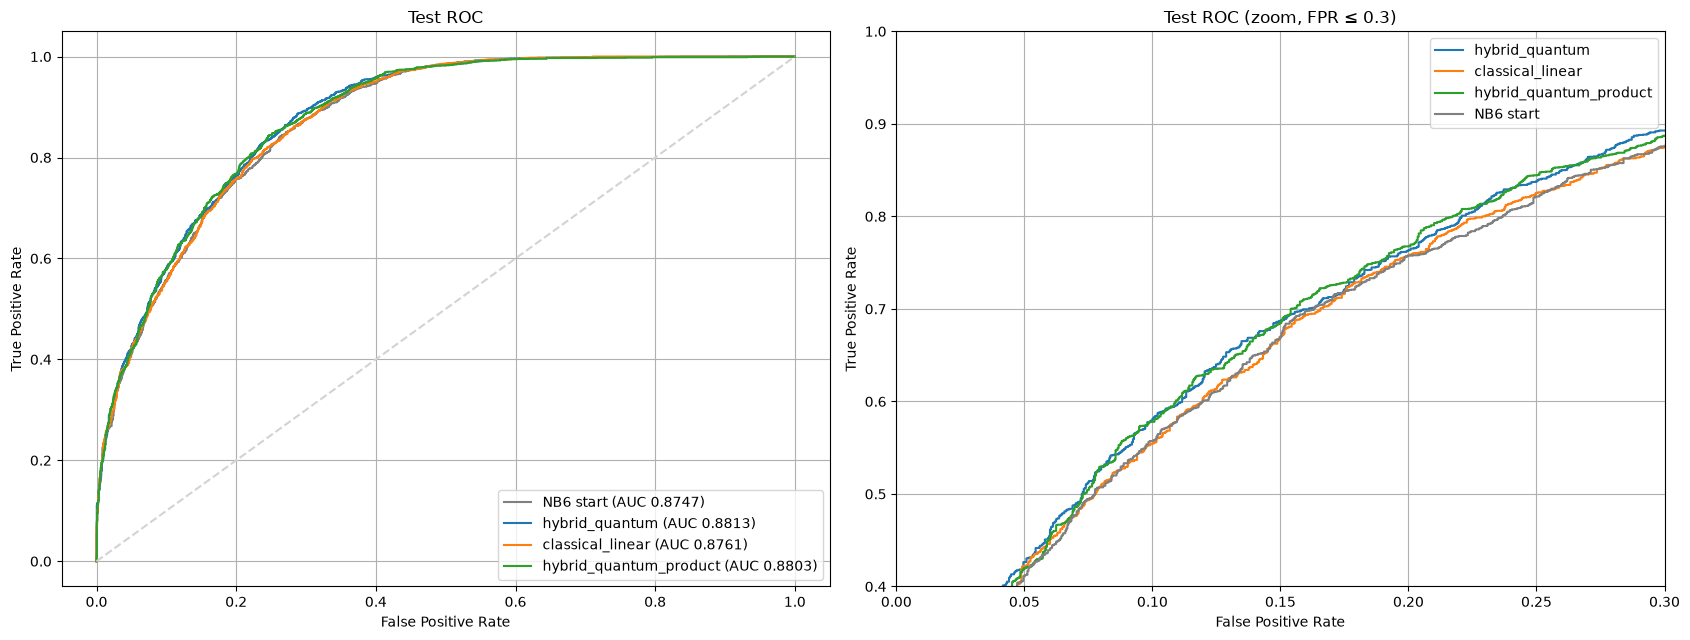

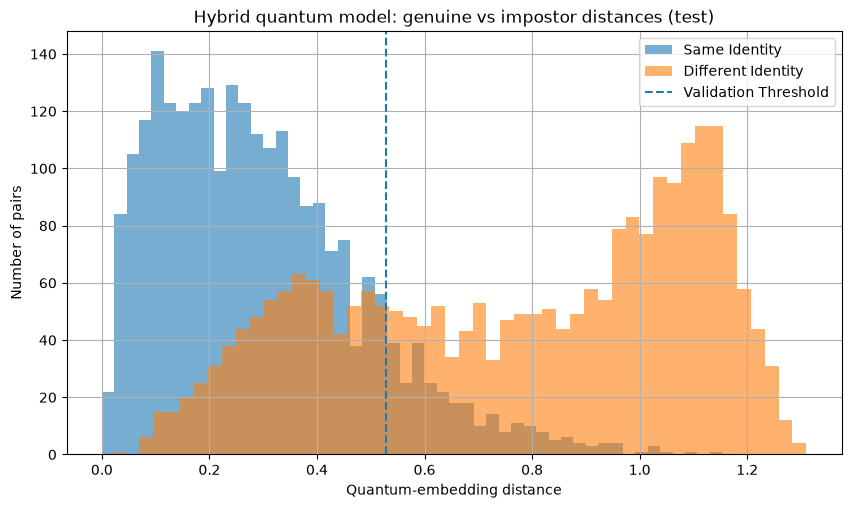

In [16]:
# ============================================================
# CELL 18: ROC curves and distance distributions
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))

axes[0].plot(
    reference_test_metrics["fpr"], reference_test_metrics["tpr"],
    color="gray", label=f"NB6 start (AUC {reference_test_metrics['auc']:.4f})"
)

for variant, result in variant_results.items():

    axes[0].plot(result["fpr"], result["tpr"],
                 label=f"{variant} (AUC {result['test_auc']:.4f})")

axes[0].plot([0, 1], [0, 1], linestyle="--", color="lightgray")

axes[0].set_xlabel("False Positive Rate")

axes[0].set_ylabel("True Positive Rate")

axes[0].set_title("Test ROC")

axes[0].legend()

axes[0].grid(True)


# zoom on the low-FPR region used in practice

for variant, result in variant_results.items():

    axes[1].plot(result["fpr"], result["tpr"], label=variant)

axes[1].plot(reference_test_metrics["fpr"], reference_test_metrics["tpr"],
             color="gray", label="NB6 start")

axes[1].set_xlim(0, 0.3)

axes[1].set_ylim(0.4, 1.0)

axes[1].set_xlabel("False Positive Rate")

axes[1].set_ylabel("True Positive Rate")

axes[1].set_title("Test ROC (zoom, FPR ≤ 0.3)")

axes[1].legend()

axes[1].grid(True)

plt.tight_layout()

plt.show()


if "hybrid_quantum" in variant_results:

    result = variant_results["hybrid_quantum"]

    plt.figure(figsize=(10, 5.5))

    plt.hist(result["distances"][test_labels == 0], bins=50, alpha=0.6,
             label="Same Identity")

    plt.hist(result["distances"][test_labels == 1], bins=50, alpha=0.6,
             label="Different Identity")

    plt.axvline(result["threshold"], linestyle="--",
                label="Validation Threshold")

    plt.xlabel("Quantum-embedding distance")

    plt.ylabel("Number of pairs")

    plt.title("Hybrid quantum model: genuine vs impostor distances (test)")

    plt.legend()

    plt.grid(True)

    plt.show()

In [17]:
# ============================================================
# CELL 19: Paired bootstrap over the test pairs
# ============================================================
#
# All models are scored on the SAME 5,000 test pairs, so the right
# question is "how often does model A beat model B when the pairs are
# resampled?". Pairs are resampled with replacement; for every resample
# the AUC of both models is recomputed on the same pairs.

genuine_labels = 1 - test_labels


def bootstrap_auc_difference(distances_a, distances_b, n_samples, seed=0):

    rng = np.random.default_rng(seed)

    n = len(genuine_labels)

    auc_a, auc_b = [], []

    while len(auc_a) < n_samples:

        index = rng.integers(0, n, n)

        y = genuine_labels[index]

        if y.min() == y.max():

            continue

        auc_a.append(roc_auc_score(y, -distances_a[index]))

        auc_b.append(roc_auc_score(y, -distances_b[index]))

    auc_a, auc_b = np.array(auc_a), np.array(auc_b)

    diff = auc_a - auc_b

    return {
        "auc_a": auc_a.mean(),
        "auc_a_low": np.percentile(auc_a, 2.5),
        "auc_a_high": np.percentile(auc_a, 97.5),
        "diff_mean": diff.mean(),
        "diff_low": np.percentile(diff, 2.5),
        "diff_high": np.percentile(diff, 97.5),
        "prob_a_better": float((diff > 0).mean()),
    }


all_distances = {"reference_nb6": reference_test_distances}

for variant, result in variant_results.items():

    all_distances[variant] = result["distances"]


comparisons = [
    ("hybrid_quantum", "reference_nb6"),
    ("classical_linear", "reference_nb6"),
    ("hybrid_quantum_product", "reference_nb6"),
    ("hybrid_quantum", "classical_linear"),
    ("hybrid_quantum", "hybrid_quantum_product"),
]

rows = []

for a, b in comparisons:

    if a in all_distances and b in all_distances:

        stats = bootstrap_auc_difference(
            all_distances[a], all_distances[b], BOOTSTRAP_SAMPLES
        )

        verdict = (
            f"{a} better" if stats["diff_low"] > 0
            else f"{b} better" if stats["diff_high"] < 0
            else "no clear difference"
        )

        rows.append(
            {
                "A": a, "B": b,
                "AUC_A - AUC_B": round(stats["diff_mean"], 4),
                "95% CI low": round(stats["diff_low"], 4),
                "95% CI high": round(stats["diff_high"], 4),
                "P(A > B)": round(stats["prob_a_better"], 3),
                "verdict": verdict
            }
        )


bootstrap_df = pd.DataFrame(rows)

bootstrap_df.to_csv(OUTPUT_DIR / "paired_bootstrap_comparison.csv", index=False)

display(bootstrap_df)


# per-model AUC confidence intervals

auc_intervals = {}

for name, distances in all_distances.items():

    s = bootstrap_auc_difference(distances, distances, BOOTSTRAP_SAMPLES)

    auc_intervals[name] = (s["auc_a"], s["auc_a_low"], s["auc_a_high"])

print("\nTest AUC with 95% bootstrap interval over pairs:")

for name, (m, lo, hi) in auc_intervals.items():

    print(f"  {name:24s} {m:.4f}  [{lo:.4f}, {hi:.4f}]")

,A,B,AUC_A - AUC_B,95% CI low,95% CI high,P(A > B),verdict
0,hybrid_quantum,reference_nb6,0.0067,0.0028,0.0103,1.000,hybrid_quantum better
1,classical_linear,reference_nb6,0.0014,-0.0000,0.0028,0.972,no clear difference
2,hybrid_quantum_product,reference_nb6,0.0056,0.0018,0.0093,0.999,hybrid_quantum_product better
3,hybrid_quantum,classical_linear,0.0053,0.0015,0.0089,0.994,hybrid_quantum better
4,hybrid_quantum,hybrid_quantum_product,0.0010,-0.0009,0.0029,0.865,no clear difference



Test AUC with 95% bootstrap interval over pairs:
  reference_nb6            0.8747  [0.8652, 0.8833]
  hybrid_quantum           0.8814  [0.8721, 0.8903]
  classical_linear         0.8761  [0.8672, 0.8849]
  hybrid_quantum_product   0.8803  [0.8711, 0.8895]


,model,dim,test_accuracy,test_auc,test_eer
0,NB5 Siamese 128-D,128,0.792800,0.879686,0.219200
1,NB6 classical projection 8-D,8,0.785800,0.874688,0.221800
2,NB7 Classical linear head on frozen features,8,0.789867,0.876540,0.216667
3,NB7 Quantum VQC head on frozen features,8,0.786800,0.875533,0.218067
4,NB8 hybrid_quantum (end-to-end),8,0.799000,0.881299,0.213800
5,NB8 classical_linear (end-to-end),8,0.787200,0.876119,0.215800
6,NB8 hybrid_quantum_product (end-to-end),8,0.794200,0.880288,0.209800


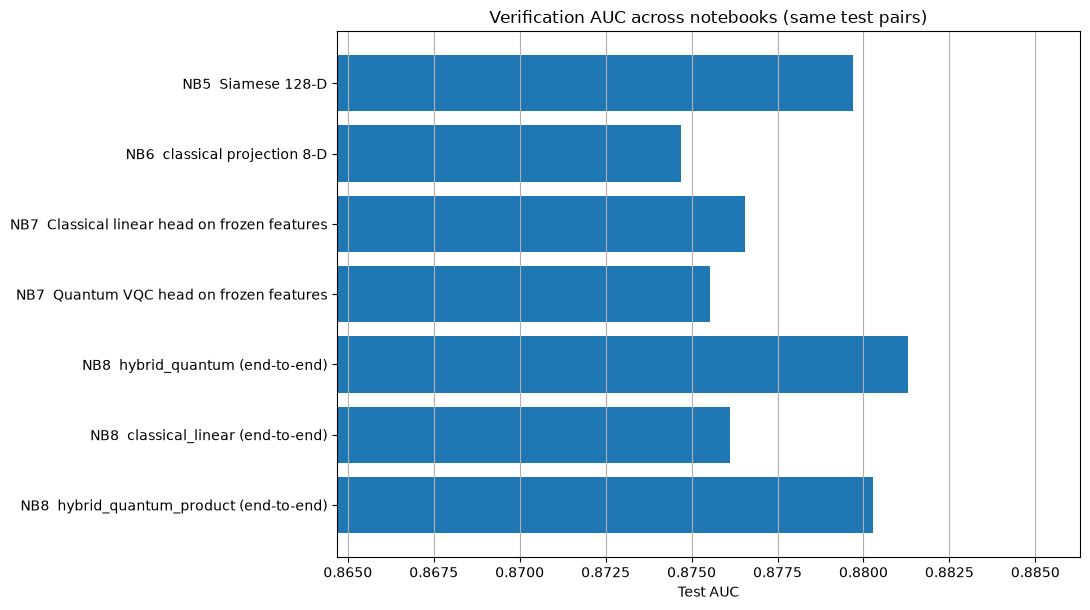

In [18]:
# ============================================================
# CELL 20: Comparison with Notebooks 5, 6 and 7
# ============================================================

rows = []

nb5_path = NB5_DIR / "final_results.csv"

if nb5_path.exists():

    nb5 = pd.read_csv(nb5_path).iloc[0]

    rows.append({"model": "NB5  Siamese 128-D", "dim": 128,
                 "test_accuracy": nb5["test_accuracy"],
                 "test_auc": nb5["test_auc"], "test_eer": nb5["test_eer"]})

rows.append({"model": "NB6  classical projection 8-D", "dim": 8,
             "test_accuracy": nb6_results["test_accuracy"],
             "test_auc": nb6_results["test_auc"],
             "test_eer": nb6_results["test_eer"]})

nb7_path = NB7_DIR / "final_comparison.csv"

if nb7_path.exists():

    nb7 = pd.read_csv(nb7_path)

    for _, row in nb7[nb7["model"].isin(
        ["Classical linear", "Quantum VQC"]
    )].iterrows():

        rows.append({"model": f"NB7  {row['model']} head on frozen features",
                     "dim": 8,
                     "test_accuracy": row["test_accuracy_mean"],
                     "test_auc": row["test_auc_mean"],
                     "test_eer": row["test_eer_mean"]})

for variant, result in variant_results.items():

    rows.append({"model": f"NB8  {variant} (end-to-end)", "dim": 8,
                 "test_accuracy": result["test_accuracy"],
                 "test_auc": result["test_auc"],
                 "test_eer": result["test_eer"]})


comparison_df = pd.DataFrame(rows)

comparison_df.to_csv(OUTPUT_DIR / "comparison_all_notebooks.csv", index=False)

display(comparison_df)


plt.figure(figsize=(11, 0.6 * len(comparison_df) + 2))

plt.barh(range(len(comparison_df)), comparison_df["test_auc"])

plt.yticks(range(len(comparison_df)), comparison_df["model"])

plt.xlim(comparison_df["test_auc"].min() - 0.01,
         comparison_df["test_auc"].max() + 0.005)

plt.gca().invert_yaxis()

plt.xlabel("Test AUC")

plt.title("Verification AUC across notebooks (same test pairs)")

plt.grid(True, axis="x")

plt.tight_layout()

plt.show()

In [19]:
# ============================================================
# CELL 21: Extract and save embeddings for few-shot evaluation
# ============================================================

class ImagePathDataset(Dataset):

    def __init__(self, paths, transform):

        self.paths = list(paths)

        self.transform = transform

    def __len__(self):

        return len(self.paths)

    def __getitem__(self, index):

        return self.transform(Image.open(self.paths[index]).convert("RGB"))


@torch.no_grad()
def extract_embeddings(model, dataframe):

    loader = DataLoader(
        ImagePathDataset(dataframe[PATH_COLUMN], evaluation_transform),
        batch_size=64, shuffle=False, num_workers=NUM_WORKERS
    )

    model.eval()

    pre, post = [], []

    for batch in tqdm(loader, desc="Embedding", leave=False):

        batch = batch.to(DEVICE)

        e_pre = model.embed_pre(batch)

        e_post = e_pre if model.head is None else model.head(e_pre)

        pre.append(e_pre.cpu().numpy())

        post.append(e_post.cpu().numpy())

    return np.concatenate(pre), np.concatenate(post)


for variant in variant_results:

    checkpoint = torch.load(
        checkpoint_path(variant), map_location=DEVICE, weights_only=False
    )

    model = build_hybrid(variant)

    model.load_state_dict(checkpoint["model_state_dict"])

    for split_name, dataframe in [
        ("train", train_df), ("validation", validation_df), ("test", test_df)
    ]:

        pre, post = extract_embeddings(model, dataframe)

        np.savez_compressed(
            OUTPUT_DIR / f"{variant}_{split_name}_embeddings.npz",
            embeddings_pre_head=pre,
            embeddings_final=post,
            identities=dataframe[IDENTITY_COLUMN].values,
            paths=dataframe[PATH_COLUMN].values
        )

    print(f"{variant:24s} embeddings saved  (final shape {post.shape})")

    del model

    if DEVICE.type == "cuda":

        torch.cuda.empty_cache()

Embedding:   0%|          | 0/219 [00:00<?, ?it/s]

Embedding:   0%|          | 0/47 [00:00<?, ?it/s]

Embedding:   0%|          | 0/47 [00:00<?, ?it/s]

hybrid_quantum           embeddings saved  (final shape (3000, 8))


Embedding:   0%|          | 0/219 [00:00<?, ?it/s]

...

classical_linear         embeddings saved  (final shape (3000, 8))


Embedding:   0%|          | 0/219 [00:00<?, ?it/s]

Embedding:   0%|          | 0/47 [00:00<?, ?it/s]

Embedding:   0%|          | 0/47 [00:00<?, ?it/s]

hybrid_quantum_product   embeddings saved  (final shape (3000, 8))


In [20]:
# ============================================================
# CELL 22: Save configuration for Notebook 9
# ============================================================

hybrid_config = {
    "seed": SEED,
    "notebook6_model_config": NB6_CONFIG,
    "notebook6_checkpoint": str(NB6_MODEL_PATH),
    "circuit_config": CIRCUIT_CONFIG,
    "quantum_sim_path": str(QUANTUM_SIM_PATH),
    "variants": {
        variant: {
            "checkpoint": str(checkpoint_path(variant)),
            "threshold": variant_results[variant]["threshold"],
            "head": VARIANT_SPECS[variant]["head"],
            "overrides": VARIANT_SPECS[variant]["overrides"],
        }
        for variant in variant_results
    },
    "contrastive_margin": CONTRASTIVE_MARGIN,
}

with open(OUTPUT_DIR / "hybrid_model_config.json", "w") as file:

    json.dump(hybrid_config, file, indent=2)


experiment_configuration = {
    "seed": SEED,
    "phase1_epochs": PHASE1_EPOCHS,
    "phase2_epochs_max": PHASE2_EPOCHS,
    "patience": PATIENCE,
    "head_lr_phase1": HEAD_LR_PHASE1,
    "head_lr_phase2": HEAD_LR_PHASE2,
    "projection_lr": PROJECTION_LR,
    "encoder_lr": ENCODER_LR,
    "weight_decay": WEIGHT_DECAY,
    "batch_size_pairs": BATCH_SIZE,
    "train_pairs_per_epoch": TRAIN_PAIRS_PER_EPOCH,
    "contrastive_margin": CONTRASTIVE_MARGIN,
    "bootstrap_samples": BOOTSTRAP_SAMPLES,
    "quick_test": QUICK_TEST,
}

pd.DataFrame([experiment_configuration]).to_csv(
    OUTPUT_DIR / "experiment_configuration.csv", index=False
)

print("Saved:")

for path in sorted(OUTPUT_DIR.iterdir()):

    print(" -", path.name)

Saved:
 - best_classical_linear_seed42.pth
 - best_hybrid_quantum_product_seed42.pth
 - best_hybrid_quantum_seed42.pth
 - classical_linear_test_embeddings.npz
 - classical_linear_train_embeddings.npz
 - classical_linear_validation_embeddings.npz
 - comparison_all_notebooks.csv
 - experiment_configuration.csv
 - final_results.csv
 - history_classical_linear_seed42.csv
 - history_hybrid_quantum_product_seed42.csv
 - history_hybrid_quantum_seed42.csv
 - hybrid_model_config.json
 - hybrid_quantum_product_test_embeddings.npz
 - hybrid_quantum_product_train_embeddings.npz
 - hybrid_quantum_product_validation_embeddings.npz
 - hybrid_quantum_test_embeddings.npz
 - hybrid_quantum_train_embeddings.npz
 - hybrid_quantum_validation_embeddings.npz
 - paired_bootstrap_comparison.csv


In [21]:
# ============================================================
# CELL 23: Final Summary
# ============================================================

print("=" * 70)

print("NOTEBOOK 8 COMPLETED SUCCESSFULLY")

print("=" * 70)

print("\nHYBRID QUANTUM METRIC LEARNING - TEST RESULTS (same pairs as NB5-7)\n")

summary_columns = ["variant", "head_parameters", "best_epoch",
                   "validation_auc", "test_accuracy", "test_auc",
                   "test_eer", "test_far", "test_frr"]

display(results_table[summary_columns])

print("\nPaired bootstrap (95% CI of the AUC difference):\n")

display(bootstrap_df)

print("\nHow to read this:")

print(" - 'no clear difference' means the CI of the AUC difference includes 0.")

print(" - Only a variant whose CI is entirely above 0 versus BOTH the")

print("   classical control and the Notebook 6 start can be called better.")

print("\nSaved to:", OUTPUT_DIR)

print("\n✓ Notebook 8 is complete.")

NOTEBOOK 8 COMPLETED SUCCESSFULLY

HYBRID QUANTUM METRIC LEARNING - TEST RESULTS (same pairs as NB5-7)



,variant,head_parameters,best_epoch,validation_auc,test_accuracy,test_auc,test_eer,test_far,test_frr
0,reference_nb6 (start),0,0,0.880773,0.7858,0.874688,0.2218,0.2516,0.1768
1,hybrid_quantum,48,32,0.882875,0.7990,0.881299,0.2138,0.2896,0.1124
2,classical_linear,64,3,0.881676,0.7872,0.876119,0.2158,0.2464,0.1792
3,hybrid_quantum_product,48,21,0.881849,0.7942,0.880288,0.2098,0.2768,0.1348



Paired bootstrap (95% CI of the AUC difference):



,A,B,AUC_A - AUC_B,95% CI low,95% CI high,P(A > B),verdict
0,hybrid_quantum,reference_nb6,0.0067,0.0028,0.0103,1.000,hybrid_quantum better
1,classical_linear,reference_nb6,0.0014,-0.0000,0.0028,0.972,no clear difference
2,hybrid_quantum_product,reference_nb6,0.0056,0.0018,0.0093,0.999,hybrid_quantum_product better
3,hybrid_quantum,classical_linear,0.0053,0.0015,0.0089,0.994,hybrid_quantum better
4,hybrid_quantum,hybrid_quantum_product,0.0010,-0.0009,0.0029,0.865,no clear difference



How to read this:
 - 'no clear difference' means the CI of the AUC difference includes 0.
 - Only a variant whose CI is entirely above 0 versus BOTH the
   classical control and the Notebook 6 start can be called better.

Saved to: ..\hybrid_quantum_metric_learning

✓ Notebook 8 is complete.


## Interpreting the outcome

| Outcome | What it means |
|---|---|
| `hybrid_quantum` CI above 0 vs `classical_linear` **and** vs Notebook 6 | The circuit helps when trained jointly - report the size of the gain with its CI. |
| `hybrid_quantum` ≈ `classical_linear` (CI contains 0), both above Notebook 6 | The gain is just extra fine-tuning; the circuit is **as good as** a classical layer with similar parameters. |
| `hybrid_quantum` ≈ `hybrid_quantum_product` | Entanglement is not contributing on this task. |
| Everything ≈ Notebook 6 | The 8-D bottleneck, not the head, limits performance. Next lever: a larger projection dimension (more qubits). |

All of these are valid conclusions. A single training seed is used per variant
(runs are long); to add training-seed variance, change `SEED` and re-run -
checkpoints are stored per seed, so nothing is overwritten.

## Notes for Notebook 9 (few-shot evaluation)

- `hybrid_model_config.json` lists every checkpoint, threshold and how to
  rebuild the model; the `build_hybrid` function in CELL 11 can be copied as is.
- `*_embeddings.npz` hold the pre-head and final 8-D embeddings of all three
  splits, so the 1/3/5-shot verification and identification protocols from
  Notebook 3 can be evaluated without re-running the CNN.
- Evaluate **all variants and Notebook 5 / 6 with the same protocol and
  support/query sets**.